# Chapter 1: Understanding the Dispute Landscape in Modern Payments

This notebook loads `disputes_sample.csv` (5,000 synthetic card disputes, one year at a representative mid-sized US issuer, scaled down 144 times) and reproduces the chapter's tables and data figures:

1. Headline figures and **Table 1.2** (annual dispute profile)
2. The three families (**Figure 1.1**, as counts and value)
3. Where the money goes (**Figure 1.3** waterfall)
4. The baseline **Dispute Ledger** (Table 1.3 levers), the chapter artifact

All data are synthetic and all amounts illustrative.

## Cell 1: load the data and the headline figures

In [1]:
import pandas as pd
disputes = pd.read_csv("disputes_sample.csv",
    parse_dates=["opened_at", "closed_at"])
summary = {
    "cases": len(disputes),
    "first_party_share": (disputes["family"] == "first_party").mean(),
    "contested_share": disputes["represented"].mean(),
    "win_rate": disputes.loc[disputes["represented"],
        "outcome"].eq("won").mean(),
    "avg_amount": disputes["amount"].mean(),
}
print(summary)

{'cases': 5000, 'first_party_share': np.float64(0.38), 'contested_share': np.float64(0.31), 'win_rate': np.float64(0.42), 'avg_amount': np.float64(186.0)}


### Table 1.2: annual dispute profile of the representative issuer

The sample covers one year; each sample case stands for 144 cases at an issuer with about 4 million active cards.

In [2]:
SCALE = 144   # 5,000 sample cases -> 720,000 cases a year
net_loss = disputes["net_loss"].sum() * SCALE
operating = disputes["handling_cost"].sum() * SCALE
table_1_2 = pd.DataFrame({"Value": [
    f"{summary['cases'] * SCALE:,}",
    f"{summary['first_party_share']:.0%}",
    f"${disputes['handling_cost'].mean():,.0f}",
    f"{summary['contested_share']:.0%}",
    f"{summary['win_rate']:.0%}",
    f"${summary['avg_amount']:,.0f}",
    f"${net_loss / 1e6:,.0f} million",
    f"${operating / 1e6:,.0f} million",
]}, index=["Dispute cases per year",
           "Share classified as first-party misuse",
           "Average handling cost per case",
           "Cases contested through representment",
           "Win rate on contested cases",
           "Average disputed amount",
           "Net annual dispute loss (unrecovered)",
           "Annual operating cost"])
table_1_2.index.name = "Metric"
table_1_2

,Value
Metric,
Dispute cases per year,"720,000"
Share classified as first-party misuse,38%
Average handling cost per case,$28
Cases contested through representment,31%
Win rate on contested cases,42%
Average disputed amount,$186
Net annual dispute loss (unrecovered),$61 million
Annual operating cost,$20 million


## The three families (Figure 1.1, in numbers)

In [3]:
families = (disputes.groupby("family")
            .agg(cases=("case_id", "size"), value=("amount", "sum"),
                 net_loss=("net_loss", "sum"))
            .reindex(["unauthorized", "defective", "first_party"]))
families["share_of_cases"] = families["cases"] / families["cases"].sum()
families["annual_cases"] = families["cases"] * SCALE
families["annual_net_loss_$m"] = families["net_loss"] * SCALE / 1e6
families.round(3)

,cases,value,net_loss,share_of_cases,annual_cases,annual_net_loss_$m
family,,,,,,
unauthorized,1550,379798.72,203346.74,0.31,223200,29.282
defective,1550,257540.30,87965.44,0.31,223200,12.667
first_party,1900,292660.98,132296.44,0.38,273600,19.051


## Cell 2: where the money goes (Figure 1.3)

From gross disputed value to net loss. *Denied* claims are re-billed to the cardholder; *accepted* chargebacks are recovered from the merchant; chargebacks whose representment failed are also recovered. What remains, written-off claims and claims where the merchant's representment succeeded, is the net loss.

                            step    $m
            Gross disputed value 133.9
 Denied, re-billed to cardholder -11.4
Chargebacks accepted by merchant -38.5
 Representment failed, recovered -23.0
                        Net loss  61.0


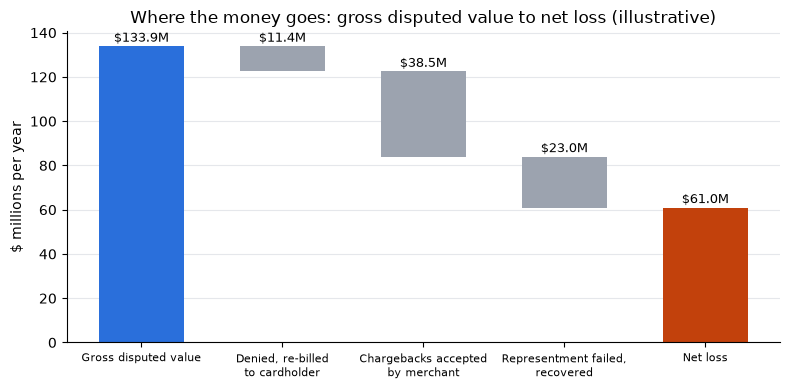

In [4]:
import matplotlib.pyplot as plt

by_outcome = disputes.groupby("outcome")["amount"].sum() * SCALE / 1e6
gross = disputes["amount"].sum() * SCALE / 1e6
steps = [
    ("Gross disputed value", gross),
    ("Denied, re-billed\nto cardholder", -by_outcome["denied"]),
    ("Chargebacks accepted\nby merchant", -by_outcome["accepted"]),
    ("Representment failed,\nrecovered", -by_outcome["lost"]),
]
net = gross + sum(v for _, v in steps[1:])
waterfall = pd.DataFrame(steps + [("Net loss", net)], columns=["step", "$m"])
print(waterfall.assign(step=waterfall["step"].str.replace("\n", " ")).round(1).to_string(index=False))

fig, ax = plt.subplots(figsize=(8, 4))
running = 0.0
for i, (label, v) in enumerate(steps + [("Net loss", net)]):
    if i == 0 or label == "Net loss":
        bottom, height, color = 0, v, "#2a6fdb" if i == 0 else "#c2410c"
        running = v
    else:
        bottom, height, color = running + v, -v, "#9ca3af"
        running += v
    ax.bar(i, height, bottom=bottom, color=color, width=0.6)
    ax.text(i, bottom + height + 2, f"${abs(v):,.1f}M", ha="center", fontsize=9)
ax.set_xticks(range(len(steps) + 1), [s for s, _ in steps] + ["Net loss"], fontsize=8)
ax.set_ylabel("$ millions per year")
ax.set_title("Where the money goes: gross disputed value to net loss (illustrative)")
ax.spines[["top", "right"]].set_visible(False)
ax.grid(axis="y", color="#e5e7eb"); ax.set_axisbelow(True)
plt.tight_layout(); plt.show()

## Cell 3: the baseline Dispute Ledger

Every dollar of the combined loss and operating cost is assigned to exactly one lever. The assignment rules used for the baseline:

| Cost | Lever | Why |
|---|---|---|
| Written-off loss on **unauthorized** claims | Prevent | stoppable at authorization |
| Written-off loss on **defective** claims | Deflect | resolvable by refund or merchant contact before it is formal |
| Written-off loss on **first-party** claims | Decide | a customer-treatment decision to accept rather than contest |
| Handling cost of every case | Decide | classification, auto-decisioning, evidence automation |
| Loss where the merchant's representment succeeded | Recover | contest quality and contest-or-accept rules |

In [5]:
def lever(row):
    if row["outcome"] == "written_off":
        return {"unauthorized": "Prevent", "defective": "Deflect",
                "first_party": "Decide"}[row["family"]]
    if row["outcome"] == "won":
        return "Recover"
    return None

loss_lever = disputes.apply(lever, axis=1)
ledger = (disputes.assign(lever=loss_lever)
          .groupby("lever")["net_loss"].sum() * SCALE / 1e6)
ledger["Decide"] += disputes["handling_cost"].sum() * SCALE / 1e6
ledger = (ledger.reindex(["Prevent", "Deflect", "Decide", "Recover"])
          .rename("annual_cost_$m").to_frame())
ledger["share"] = ledger["annual_cost_$m"] / ledger["annual_cost_$m"].sum()
ledger["chapters"] = ["6, 7", "3, 13", "8, 9, 11, 12", "10, 12"]
print(f"Combined loss and operating cost: ${ledger['annual_cost_$m'].sum():,.1f}M")
ledger.round(3)

Combined loss and operating cost: $81.2M


,annual_cost_$m,share,chapters
lever,,,
Prevent,26.979,0.332,"6, 7"
Deflect,8.106,0.100,"3, 13"
Decide,30.207,0.372,"8, 9, 11, 12"
Recover,15.867,0.196,"10, 12"


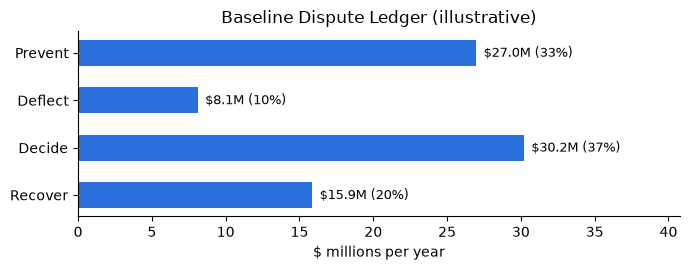

In [6]:
fig, ax = plt.subplots(figsize=(7, 2.8))
ax.barh(ledger.index[::-1], ledger["annual_cost_$m"][::-1], color="#2a6fdb", height=0.55)
for y, (v, s) in enumerate(zip(ledger["annual_cost_$m"][::-1], ledger["share"][::-1])):
    ax.text(v + 0.5, y, f"${v:,.1f}M ({s:.0%})", va="center", fontsize=9)
ax.set_xlabel("$ millions per year")
ax.set_title("Baseline Dispute Ledger (illustrative)")
ax.spines[["top", "right"]].set_visible(False)
ax.set_xlim(0, ledger["annual_cost_$m"].max() * 1.35)
plt.tight_layout(); plt.show()

Save the baseline Ledger, the chapter artifact that later chapters update.

In [7]:
ledger.round(4).to_csv("baseline_ledger.csv")
print(open("baseline_ledger.csv").read())

lever,annual_cost_$m,share,chapters
Prevent,26.9789,0.3324,"6, 7"
Deflect,8.1065,0.0999,"3, 13"
Decide,30.2074,0.3722,"8, 9, 11, 12"
Recover,15.8668,0.1955,"10, 12"

